# Practical 6: reading enhancers with a deep learning model

**ISN Neurochemistry School 2026**

Practical 5 found regions that are open in one cell type and closed in others.
You know *where* they are, not *why*. The sequence should carry the answer: a
region is open in a Kenyon cell because it contains motifs that Kenyon cell
transcription factors bind.

> Given only 500 nucleotides, can a model tell which cell type a region is open
> in, and which nucleotides did it use to decide?

Nothing is trained here. Both models are pretrained and each prediction takes
under a second on a laptop.

Three parts are marked *optional*. Nothing later depends on them.

## Where this data comes from

Nothing here is our data, and neither model was trained by us.

| what | from | link |
|---|---|---|
| **DeepFlyBrain** model | Janssens et al. 2022, *Nature* 601:630 | via `crested.get_model`, <https://flybrain.aertslab.org> |
| **Embryo10x** model | Dickmanken et al. 2026, *Nat Commun* | via `crested.get_model`, GEO GSE293575 |
| adult brain ATAC tracks | Janssens et al. 2022 | <https://flybrain.aertslab.org/downloads/>, GEO GSE163697 |
| the 54 enhancers tested in flies | Janssens et al. 2022, Figure 4 | `downloads/other/enhancersTested.bed` at that portal |
| embryo ATAC tracks | Dickmanken et al. 2026 | <https://ucsctracks.aertslab.org/papers/hydrop_v2_paper/> |
| motif database | CREsted | via `crested.get_motif_db` |
| dm6 genome | UCSC | <https://hgdownload.soe.ucsc.edu/goldenPath/dm6/bigZips/> |

CREsted itself is Kempynck, De Winter et al. 2026, *Nature Methods*:
<https://crested.readthedocs.io>. `scripts/download_data.py` prints every URL as
it fetches, so you can trace any number back to its source. Please cite the
groups that published the data, not the course.

## Running on Google Colab

Run this cell first.

In [1]:
# Colab setup. On a laptop install this cell does nothing.
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    import os

    !pip install -q "crested[motif]" tangermeme pyBigWig "pandas==2.2.3"

    # Get the course files, or update them if this session already has them.
    # Re-running this cell, or opening both practicals in one session, is fine.
    import subprocess

    if os.path.isdir("/content/course/.git"):
        # An update is refused if anything in that folder has been edited.
        # Stopping here would be unhelpful and discarding the edit silently
        # would be worse, so report it and carry on with what is already there.
        update = subprocess.run(
            ["git", "-C", "/content/course", "pull", "--quiet", "--ff-only"],
            capture_output=True, text=True,
        )
        if update.returncode:
            print("Could not update the course files. Continuing with the copy")
            print("already in this session, which is almost certainly fine.")
    else:
        !rm -rf /content/course
        !git clone -q https://github.com/nkempynck/isn-school-2026 /content/course
    %cd /content/course
    print("Ready.")
else:
    print("Running locally, nothing to install.")

Running locally, nothing to install.


## 0. Setup

Two environment variables must be set **before** anything is imported.
`KERAS_BACKEND` tells Keras to use PyTorch, and `KERAS_TORCH_DEVICE` keeps the
computation on the CPU.

In [2]:
import os

os.environ["KERAS_BACKEND"] = "torch"
os.environ["KERAS_TORCH_DEVICE"] = "cpu"

import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import crested

# Loading these two parts of crested switches matplotlib to a file-only
# backend, which stops figures appearing in the notebook. Load them now and
# then restore the notebook backend, so that every plot below is displayed.
_ = crested.tl, crested.pl
%matplotlib inline
import matplotlib.pyplot as plt

print("crested", crested.__version__)

2026-10-21T17:20:58.025061+0200 INFO Lazily importing module crested.tl. This could take a second...


2026-10-21T17:21:07.482979+0200 INFO Lazily importing module crested.pl. This could take a second...


crested 1.10.0


## 1. The first model

**DeepFlyBrain** was trained by Janssens et al. on the same adult brain ATAC data
you used in Practical 5. It takes **500 base pairs of DNA** and returns **81
numbers between 0 and 1**.

Each output is a **topic**: a group of regions that tend to be open in the same
cells. The authors found these groups first, then trained the model to recognise
them from sequence alone.

In [3]:
model_path, output_names = crested.get_model("DeepFlyBrain")
model = crested.utils.load_model(model_path, compile=False)

print("input shape: ", model.input_shape)
print("output shape:", model.output_shape)
print("first outputs:", output_names[:5])

input shape:  (None, 500, 4)
output shape: (None, 81)
first outputs: ['Topic_1', 'Topic_2', 'Topic_3', 'Topic_4', 'Topic_5']


### Topics are not cell types

The outputs are called `Topic_1` to `Topic_81`, which says nothing on its own.
The authors annotated only a minority of them with the cell type they
correspond to and left the rest unlabelled. `scripts/deepflybrain_topics.py` holds that table,
taken from the legend on the flybrain.aertslab.org portal.

In [4]:
from scripts.deepflybrain_topics import TOPIC_CELL_TYPE

annotated = sorted(TOPIC_CELL_TYPE)
topic_index = [n - 1 for n in annotated]                       # positions in the output
topic_labels = [f"{TOPIC_CELL_TYPE[n]} ({n})" for n in annotated]

print(f"{len(annotated)} of 81 topics have a cell type.")
print(f"The other {81 - len(annotated)} were never annotated, "
      f"so a high score there cannot be read.")

25 of 81 topics have a cell type.
The other 56 were never annotated, so a high score there cannot be read.


The annotated topics cover Kenyon cells, T neurons and glia, the cells the model
was trained on. Three correspond to BEAF-32, an insulator protein rather than a
cell type.

## 2. The genome

To turn a region such as `chr2R:19346269-19346769` into 500 nucleotides we need
the dm6 genome sequence.

In [5]:
from scripts.download_data import dm6_genome

genome = crested.Genome(dm6_genome())
crested.register_genome(genome)

  already here: dm6.fa (147 MB)
2026-10-21T17:21:07.895501+0200 INFO Genome dm6 registered.


## 3. The regions from Practical 5

Practical 5 exported two regions, one open specifically in Kenyon cells and one
in astrocytes. Each is exactly 500 bp, the size both models expect.

They are written out below. If you chose different regions in Practical 5,
replace the coordinates with your own.

In [6]:
# The two regions exported by Practical 5. Replace them with your own if you
# picked different ones.
kc_region = "chr2R:19346269-19346769"      # open specifically in Kenyon cells
glia_region = "chr3R:18232201-18232701"    # open specifically in astrocytes

kc_seq, glia_seq = crested.utils.fetch_sequences([kc_region, glia_region], genome)
print("Kenyon cell region:", kc_region, len(kc_seq), "bp")
print("glial region:      ", glia_region, len(glia_seq), "bp")

Kenyon cell region: chr2R:19346269-19346769 500 bp
glial region:       chr3R:18232201-18232701 500 bp


## 4. Asking the model what a region is

Start with the glial region, the one near `repo`. If the model works, the
glial topics should be the tall ones.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


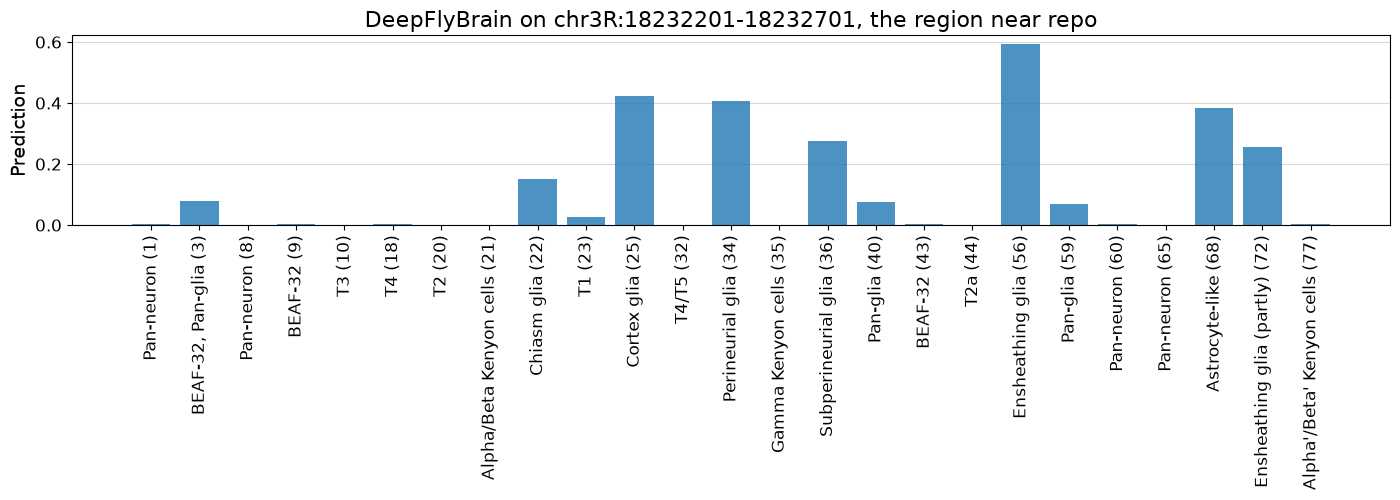

In [7]:
glia_prediction = crested.tl.predict(glia_seq, model).ravel()

crested.pl.region.bar(
    data=glia_prediction[topic_index],
    classes=topic_labels,
    title=f"DeepFlyBrain on {glia_region}, the region near repo",
    width=14, height=5, xtick_rotation=90,
)

Every glial topic has a bar: ensheathing, cortex, perineurial, astrocyte-like,
subperineurial and chiasm glia. Every Kenyon cell and T neuron topic sits at
zero.

The model saw 500 nucleotides and nothing else, and placed the region in glia.
It says "glia" rather than "astrocyte" because glial types share much of their
regulatory programme, which is a reasonable answer rather than a failure.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


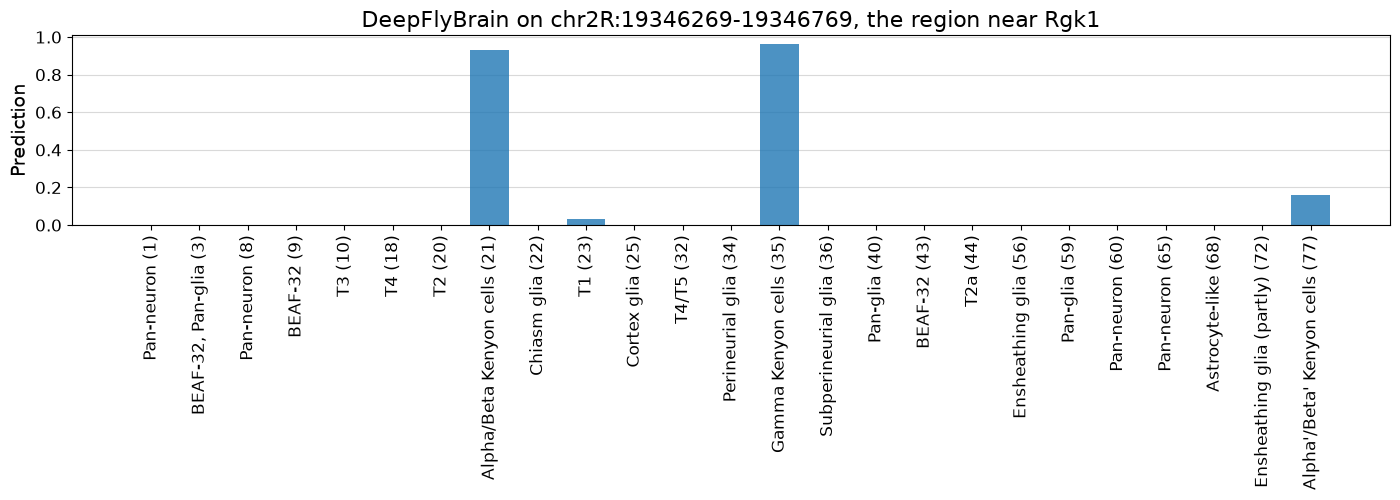

In [8]:
kc_prediction = crested.tl.predict(kc_seq, model).ravel()

crested.pl.region.bar(
    data=kc_prediction[topic_index],
    classes=topic_labels,
    title=f"DeepFlyBrain on {kc_region}, the region near Rgk1",
    width=14, height=5, xtick_rotation=90,
)

The pattern is inverted: Kenyon cell topics are now the tall bars, gamma Kenyon
reaching about 0.96, and the glial topics have dropped to zero. Same model, two
sequences, opposite answers.

This region sits beside `Rgk1`, which Practical 5 found to be one of the
strongest gamma Kenyon markers. The gene is expressed in Kenyon cells, the
region beside it is open in Kenyon cells, and the model reaches the same
conclusion from the 500 nucleotides alone.

Count that carefully. DeepFlyBrain was trained on the accessibility data you
looked at in Practical 5, so the model agreeing with that data is not
independent confirmation of it. The two independent measurements here are
expression and accessibility. What the model adds is different: that the
information is in the sequence.

## 5. A second model, trained on different cells

**Embryo10x** was trained by Dickmanken et al. (2026) on ATAC data from whole
*Drosophila* embryos, 16 to 20 hours after egg laying. It also takes 500 bp of
dm6. Two differences matter:

- its 20 outputs are **named cell types**, so no lookup table is needed
- it predicts **peak height**, not a probability. Compare rankings within a
  model, never numbers between models.

In [9]:
embryo_path, embryo_classes = crested.get_model("Embryo10x")
embryo_model = crested.utils.load_model(embryo_path, compile=False)

embryo_classes = list(embryo_classes)
print(len(embryo_classes), "cell types, named directly:")
print(", ".join(embryo_classes))

20 cell types, named directly:
Epidermis, Fat_body, Glia, Head_Ectoderm, Hemocytes, Hindgut, Malpighian_Tubule, Midgut, Midgut_acidification, Neuroblasts, Neuronal, PNS_sens_neurons, Pharynx, Primordium_all, Salivary_gland, Somatic_muscles, Tracheal_system, Visceral_muscles, Yolk, muscle_attachment_Stripe


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


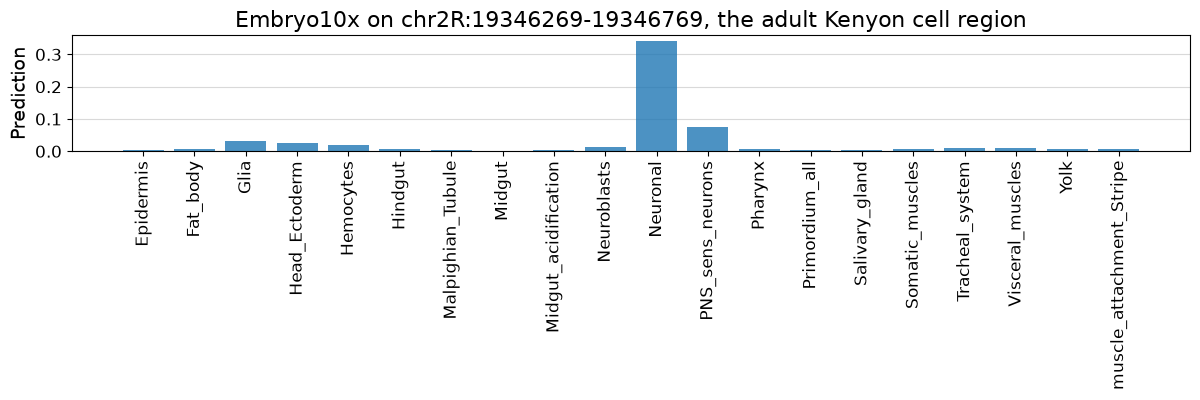

In [10]:
crested.pl.region.bar(
    data=crested.tl.predict(kc_seq, embryo_model).ravel(),
    classes=embryo_classes,
    title=f"Embryo10x on {kc_region}, the adult Kenyon cell region",
    width=12, height=4, xtick_rotation=90,
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


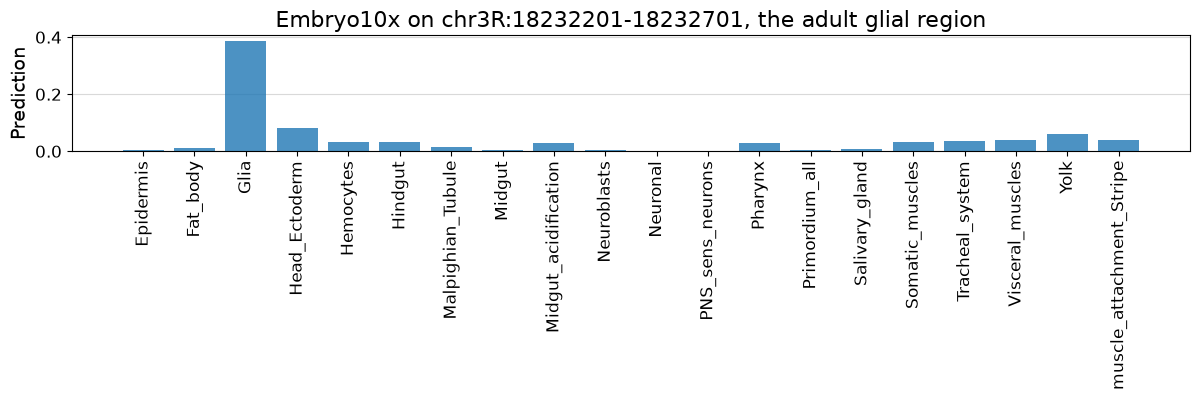

In [11]:
crested.pl.region.bar(
    data=crested.tl.predict(glia_seq, embryo_model).ravel(),
    classes=embryo_classes,
    title=f"Embryo10x on {glia_region}, the adult glial region",
    width=12, height=4, xtick_rotation=90,
)

The embryo model puts `Neuronal` on top for the Kenyon cell region and `Glia` on
top for the glial region. It has never seen an adult brain, yet it still
separates neuronal from glial sequence.

What it cannot do is go further. Its best answer for the Kenyon region is
"Neuronal", because its training data contained no Kenyon cells.

> A model can only answer about the cell types it was trained on.

### Checking the model against the data it learned from

Both answers above are the model's opinion. The data it was trained on is
public, so we can check directly.

These tracks are large, so they are read over the network one locus at a time,
as in Practical 5, rather than downloaded.

Dickmanken et al. 2026 - embryo scATAC bigwigs (16-20 h AEL)


  reading 3 track(s) over the network, not downloading


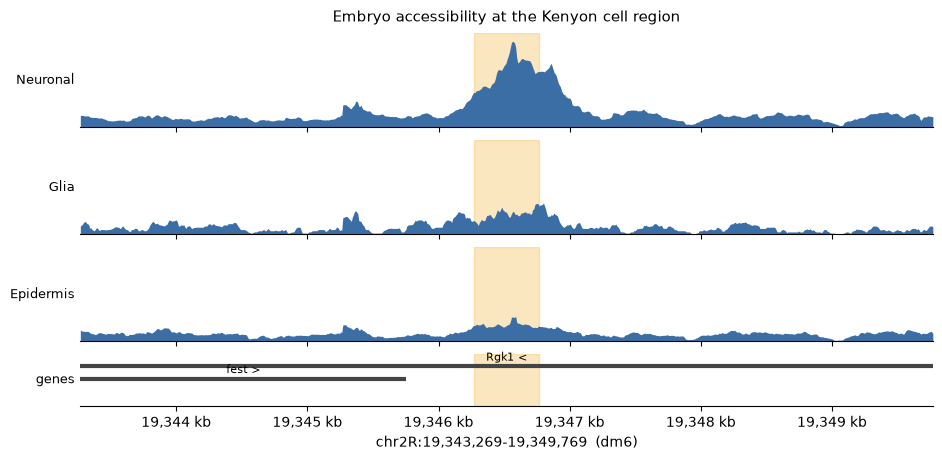

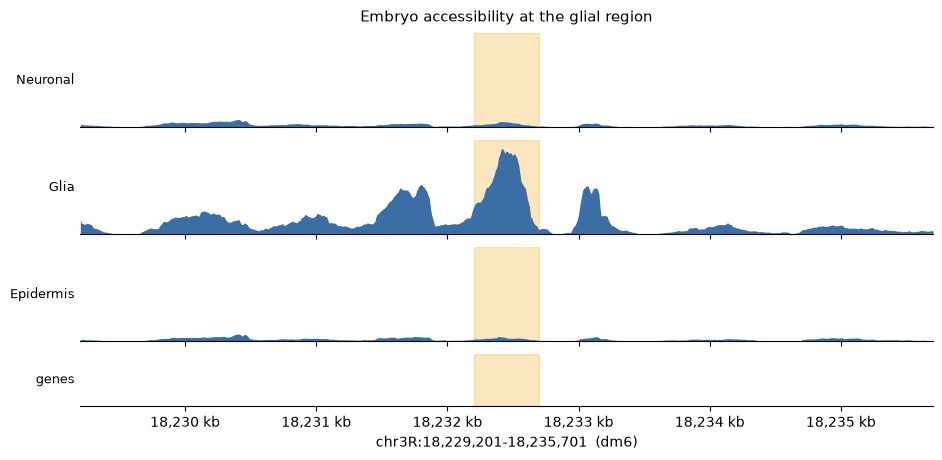

In [12]:
from scripts.download_data import dickmanken_embryo_bigwigs
from scripts.plots import plot_tracks

# Three of the twenty embryo cell types. Pass EMBRYO_CELL_TYPES for all of them.
embryo_tracks = dickmanken_embryo_bigwigs(["Neuronal", "Glia", "Epidermis"])

for region, description in [(kc_region, "Kenyon cell region"),
                            (glia_region, "glial region")]:
    chrom, span = region.split(":")
    start, end = (int(x) for x in span.split("-"))
    plot_tracks(embryo_tracks, region=(chrom, start - 3_000, end + 3_000),
                highlight=(start, end),
                title=f"Embryo accessibility at the {description}")
    plt.show()

The highlighted region is the one given to the model, and the data agrees with
it. At the glial region, embryonic glia carry about 3.6 times their local
background and fifteen times the signal of embryonic neurons. At the Kenyon cell
region the order reverses.

So these adult brain regions are already open in the matching embryonic cell
type, at a stage when the first Kenyon cells are only just being born. The four
mushroom body neuroblasts are specified during embryogenesis and the gamma
Kenyon cells are their earliest progeny, so this is the beginning of the
mushroom body rather than a time before it.

One caution for the projects: these embryo files call it `3R` where the Janssens
files say `chr3R`. `plot_tracks` accepts either, but your own code will need
to.

## 6. Which nucleotides matter?

A prediction summarises all 500 nucleotides in a single number. The
contribution of each position to that number can be recovered separately.

For that we switch to regions the authors tested **in the fly**: 54 candidate
enhancers cloned in front of a reporter gene, in `enhancersTested.bed`. For an
arbitrary region we could not judge whether the model's explanation is sensible.
For these, activity was measured.

In [13]:
from scripts.download_data import janssens_tested_enhancers

tested = pd.read_csv(janssens_tested_enhancers(), sep="\t", header=None,
                     names=["chrom", "start", "end", "name"])
tested["centre"] = (tested["start"] + tested["end"]) // 2
tested["region"] = (tested["chrom"] + ":" + (tested["centre"] - 250).astype(str)
                    + "-" + (tested["centre"] + 250).astype(str))

print(len(tested), "enhancers tested in vivo")
tested.head()

Janssens et al. 2022 - enhancers tested in vivo
  already here: enhancersTested.bed (0.0 MB)
54 enhancers tested in vivo


,chrom,start,end,name,centre,region
0,chrX,18552058,18553789,enh14,18552923,chrX:18552673-18553173
1,chr3L,9525431,9526414,enh19,9525922,chr3L:9525672-9526172
2,chr2R,10442344,10442886,enh21,10442615,chr2R:10442365-10442865
3,chr2L,20050798,20051699,enh49,20051248,chr2L:20050998-20051498
4,chr3R,11450825,11451124,enh60,11450974,chr3R:11450724-11451224


Start with **enh47**, the one Figure 4 of the paper dissects. It lies near
*sNPF*, the reporter is active in gamma Kenyon cells, and the figure annotates
four transcription factor motifs in it: **Sr**, **Mef2**, **Ey** and **Onecut**.
Mutating the Ey and Mef2 sites reduces its activity.

Because the answer is known in advance, this is a fair test of the method rather
than a demonstration.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


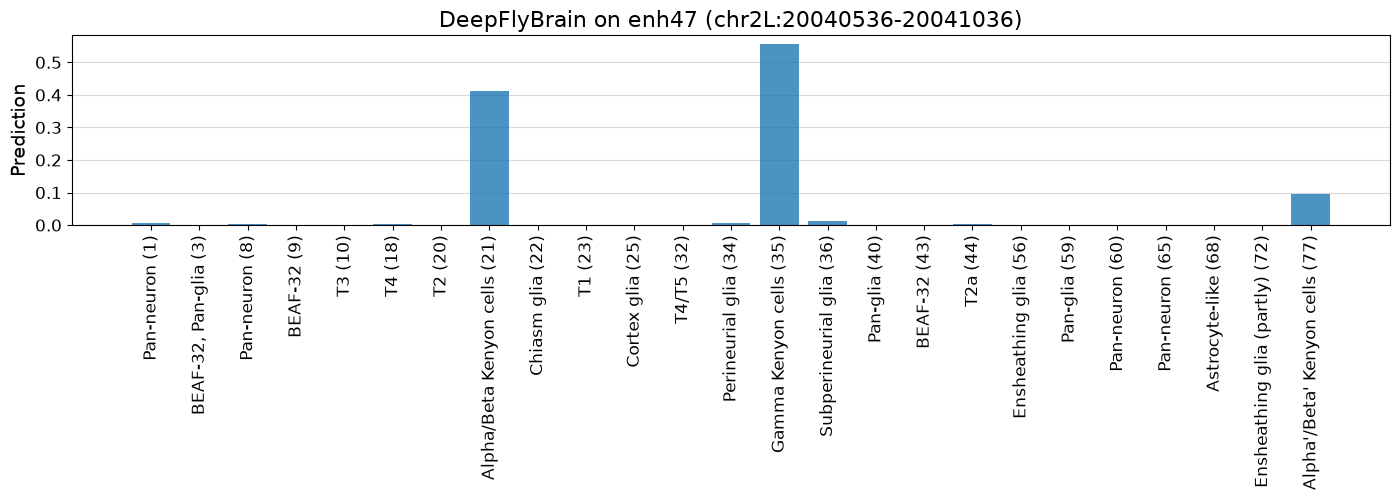

In [14]:
enh_name = "enh47"
enh_region = tested.loc[tested["name"] == enh_name, "region"].iloc[0]
enh_seq = crested.utils.fetch_sequences([enh_region], genome)[0]

crested.pl.region.bar(
    data=crested.tl.predict(enh_seq, model).ravel()[topic_index],
    classes=topic_labels,
    title=f"DeepFlyBrain on {enh_name} ({enh_region})",
    width=14, height=5, xtick_rotation=90,
)

### Contribution scores

A **contribution score** gives every nucleotide a value: positive if it pushes
the prediction up, negative if it pushes it down. CREsted computes them with
expected integrated gradients, which compares the sequence against a set of
reference sequences rather than a single blank one. That is close to the method
the paper used, and it takes a couple of seconds.

`target_idx` chooses which of the 81 outputs to explain, counting from zero, so
`Topic_35` is index 34.

In [15]:
enh_scores, enh_onehot = crested.tl.contribution_scores(
    [enh_seq],
    target_idx=34,                  # Topic_35, gamma Kenyon cells
    model=model,
    method="expected_integrated_grad",
    simplex_correction=True,
    genome=genome,
)

def importance(scores):
    """How much the model depends on each nucleotide, ignoring direction."""
    return np.abs(scores[0, 0]).sum(axis=1)

imp = importance(enh_scores)
print("contributions computed:", enh_scores.shape)

2026-10-21T17:21:11.202956+0200 INFO Calculating contribution scores for 1 region(s) and 1 class(es).


Model:   0%|          | 0/1 [00:00<?, ?it/s]

Model: 100%|██████████| 1/1 [00:02<00:00,  2.60s/it]

Model: 100%|██████████| 1/1 [00:02<00:00,  2.60s/it]

contributions computed: (1, 1, 500, 4)


### Which motifs are there?

CREsted ships a database of 7,446 known motifs mapped to fly transcription
factors. `scripts/motifs.py` takes a named factor and scans the sequence on both
strands.

A 500 bp sequence contains matches to something by chance, so finding a motif is
not enough. The useful question is whether a match sits where the model is
looking, so each hit is scored by how far its contribution exceeds the average
for this sequence.

In [16]:
from scripts.motifs import scan

def motifs_the_model_uses(sequence, contributions, tfs, threshold=0.75, min_ratio=1.5):
    """Motif matches that also carry above-average contribution."""
    per_base = importance(contributions)
    hits = scan(sequence, tfs, threshold=threshold)
    if not len(hits):
        return hits
    hits["x_average"] = [
        round(float(per_base[h.start:h.end].mean() / per_base.mean()), 2)
        for h in hits.itertuples()
    ]
    # Keep only sites the model actually leans on, then take each factor's best
    # sequence match among those. Doing it the other way round lets a factor
    # claim a neighbour's site: these motifs are all AT-rich and cross-match, so
    # ranking by contribution alone labelled the Mef2 site as Onecut.
    used = hits[hits["x_average"] >= min_ratio]
    return (used.sort_values("score", ascending=False)
                .drop_duplicates("tf")
                .sort_values("start")
                .reset_index(drop=True))

found = motifs_the_model_uses(enh_seq, enh_scores, ["Mef2", "ey", "sr", "onecut"])
found

,tf,start,end,strand,sequence,score,x_average
0,sr,294,301,-,ACCCCAA,0.841,1.73
1,Mef2,307,318,+,CTATTAATAAA,0.970,3.38
2,ey,338,349,-,TAATTAAGCTA,0.823,3.54
3,onecut,347,355,-,TATCGATT,0.985,2.60


### Marking them on the plot

`highlight_positions` draws a box at given coordinates. The plotting function
returns its figure and axes, so the transcription factor name can be written
above each box.

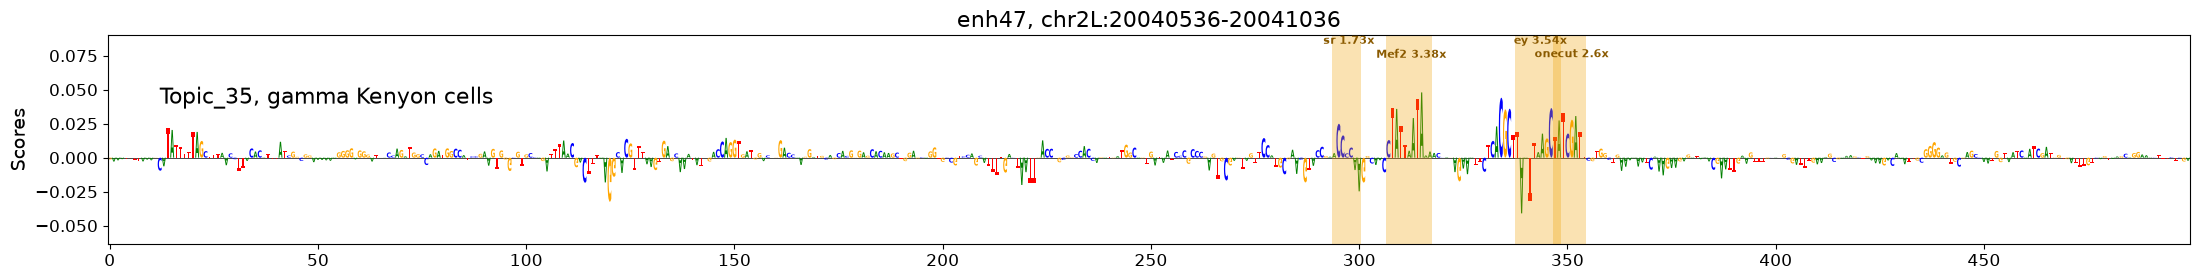

In [17]:
def plot_with_motifs(scores, onehot, hits, label, class_label, width=22, height=3):
    fig, axes = crested.pl.explain.contribution_scores(
        scores, onehot,
        sequence_labels=[label], class_labels=[class_label],
        highlight_positions=[(int(h.start), int(h.end)) for h in hits.itertuples()],
        highlight_kws={"facecolor": "#f0a202", "alpha": 0.30, "edgecolor": "none"},
        width=width, height=height, show=False,
    )
    ax = axes[0] if isinstance(axes, (list, np.ndarray)) else axes

    # Motifs often sit within a few nucleotides of each other, so a single row
    # of labels runs together and becomes unreadable. Draw them, measure how
    # wide each one really is, then stack any that would collide onto separate
    # rows in headroom added above the logo. The y position is given as a
    # fraction of the axis height so that changing the limits cannot move it.
    from matplotlib.backends.backend_agg import FigureCanvasAgg

    ordered = sorted(hits.itertuples(), key=lambda r: r.start)
    labels = [
        ax.text((h.start + h.end) / 2, 1.0, f"{h.tf} {h.x_average}x", ha="center",
                va="top", fontsize=8, weight="bold", color="#8a5a00",
                transform=ax.get_xaxis_transform())
        for h in ordered
    ]
    fig.canvas.draw()
    # crested switches the matplotlib backend, and not every backend can
    # measure text, so fall back to one that always can.
    get = getattr(fig.canvas, "get_renderer", None)
    renderer = get() if get else FigureCanvasAgg(fig).get_renderer()

    to_data = ax.transData.inverted()
    margin = onehot.shape[-2] * 0.01          # keep a nucleotide or two clear
    rows, row_of, tallest = [], [], 0
    for text in labels:
        box = text.get_window_extent(renderer)
        left = to_data.transform((box.x0, 0))[0] - margin
        right = to_data.transform((box.x1, 0))[0] + margin
        tallest = max(tallest, box.height)
        row = 0
        while row < len(rows) and left < rows[row]:
            row += 1                           # that row is still occupied here
        if row == len(rows):
            rows.append(right)
        else:
            rows[row] = right
        row_of.append(row)

    # Free up the top of the plot so the labels never sit on the sequence.
    row_height = tallest * 1.15 / ax.get_window_extent().height
    band = min(row_height * len(rows), 0.6)
    low, high = ax.get_ylim()
    ax.set_ylim(low, low + (high - low) / (1 - band))
    for text, row in zip(labels, row_of):
        text.set_y(1.0 - row * row_height)

    plt.show()

plot_with_motifs(enh_scores, enh_onehot, found,
                 f"{enh_name}, {enh_region}", "Topic_35, gamma Kenyon cells")

All four motifs Figure 4 annotates are recovered, in the paper's order: **Sr**,
**Mef2**, **Ey**, **Onecut**. Each carries between 1.7 and 3.5 times the average
contribution for this sequence, so these are positions the model depends on. Ey
and Mef2 are the two the authors mutated, and mutating them reduced the
enhancer's activity.

The model was never told what these motifs look like. It learned them from
accessibility data alone.

### The same question asked with a standard tool

> **Optional.**

Our scan keeps matches above a fraction of the best score a matrix can give.
That is easy to follow but says nothing about how often such a match arises by
chance. **FIMO**, from the MEME suite, reports a p-value instead, so one
threshold means the same thing for every motif.

In [18]:
from scripts.motifs import fimo_scan

# The same sequence, the same four factors, the standard tool.
fimo_scan(enh_seq, ["Mef2", "ey", "sr", "onecut"], p_value=1e-3)


,tf,start,end,strand,score,p_value
0,Mef2,12,23,-,9.233972,0.000049
1,Mef2,13,24,+,2.756994,0.000375
2,sr,92,99,+,11.882263,0.000061
3,onecut,140,148,-,8.352101,0.000305
4,onecut,219,227,-,6.025959,0.000870
5,Mef2,306,317,-,8.476936,0.000065
6,Mef2,307,318,+,14.043626,0.000009
7,onecut,347,355,-,13.108001,0.000015
8,ey,381,392,+,6.244415,0.000199
9,onecut,456,464,+,8.489384,0.000275


FIMO finds Mef2 at 307 and Onecut at 347, where our scan put them. Figure 4's Sr
and Ey sites do not reach significance at all. Both factors have significant
hits elsewhere, and the contribution scores are the point:

| factor | FIMO's hit | contribution | Figure 4's site | contribution |
|---|---|---|---|---|
| Sr | 92 | 0.78x | 294 | 1.73x |
| Ey | 381 | 0.82x | 338 | 3.54x |

**The hits FIMO can see are the ones the model ignores. The sites the model
leans on hardest are the ones FIMO cannot see.**

The paper is not wrong: the authors mutated those sites and the enhancer lost
activity. They are simply poor matches to the matrix, which is an average over
many binding sites. A real binding site is often a weak match, and the best
match in a sequence is often not bound at all.

So neither scan is the answer by itself. What singles out these positions is
that the model leans on them, and that mutating two of them changed the animal.

### The same sequence, a different question

A contribution score is not a property of the sequence alone. It answers *which
nucleotides support this particular output?* Ask about a cell type the enhancer
is not active in, and the answer changes.

In [19]:
wrong_scores, _ = crested.tl.contribution_scores(
    [enh_seq], target_idx=55, model=model,        # Topic_56, ensheathing glia
    method="expected_integrated_grad",
    simplex_correction=True, genome=genome,
)

embryo_scores, _ = crested.tl.contribution_scores(
    [enh_seq], target_idx=embryo_classes.index("Neuronal"), model=embryo_model,
    method="expected_integrated_grad",
    simplex_correction=True, genome=genome,
)

2026-10-21T17:21:15.059980+0200 INFO Calculating contribution scores for 1 region(s) and 1 class(es).


Model:   0%|          | 0/1 [00:00<?, ?it/s]

Model: 100%|██████████| 1/1 [00:02<00:00,  2.15s/it]

Model: 100%|██████████| 1/1 [00:02<00:00,  2.15s/it]

2026-10-21T17:21:17.215521+0200 INFO Calculating contribution scores for 1 region(s) and 1 class(es).


Model:   0%|          | 0/1 [00:00<?, ?it/s]

Model: 100%|██████████| 1/1 [00:08<00:00,  8.13s/it]

Model: 100%|██████████| 1/1 [00:08<00:00,  8.13s/it]

One adjustment first. The two models produce numbers on very different scales,
so on a shared axis the embryo row would look empty. Scaling each row by its own
maximum fixes that: the **shapes** are then comparable, the **heights** are
not.

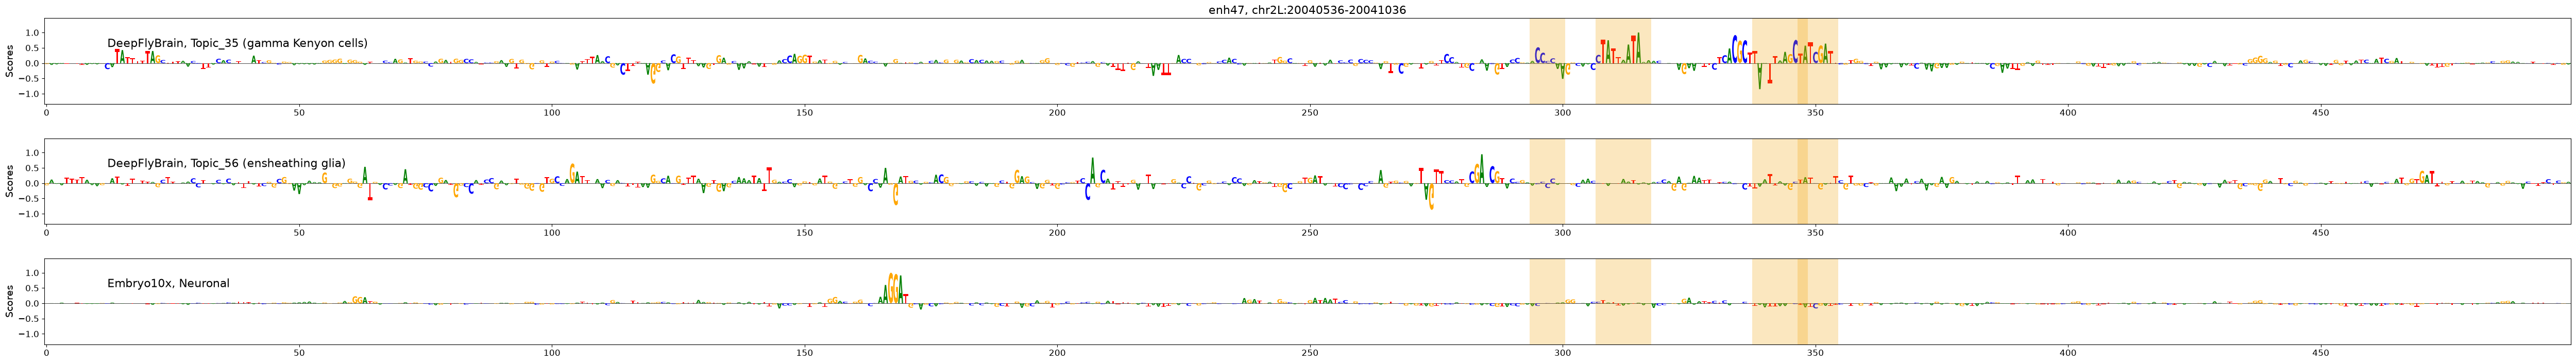

In [20]:
def scale(scores):
    """Rescale one model's contributions so its row fills the axis."""
    return scores / np.abs(scores).max()

three = np.concatenate([scale(enh_scores), scale(wrong_scores), scale(embryo_scores)],
                       axis=1)

crested.pl.explain.contribution_scores(
    three, enh_onehot,
    sequence_labels=[f"{enh_name}, {enh_region}"],
    class_labels=[
        "DeepFlyBrain, Topic_35 (gamma Kenyon cells)",
        "DeepFlyBrain, Topic_56 (ensheathing glia)",
        "Embryo10x, Neuronal",
    ],
    highlight_positions=[(int(h.start), int(h.end)) for h in found.itertuples()],
    highlight_kws={"facecolor": "#f0a202", "alpha": 0.25, "edgecolor": "none"},
)

The same four sites are boxed in all three rows, so the rows can be compared
position by position.

- **Top.** Asked about gamma Kenyon cells, the correct cell type, the model
  leans on the boxed sites
- **Middle.** Asked about ensheathing glia, the same model reads the same
  sequence and uses different positions
- **Bottom.** The embryo model, asked about generic neurons, uses different
  nucleotides again

### Putting a number on it

> **Optional.**

In [21]:
def agreement(scores_a, scores_b, n_top=40):
    a, b = importance(scores_a), importance(scores_b)
    shared = len(set(np.argsort(a)[-n_top:]) & set(np.argsort(b)[-n_top:]))
    return np.corrcoef(a, b)[0, 1], shared

corr, shared = agreement(enh_scores, embryo_scores)
print(f"{enh_name}, DeepFlyBrain (gamma Kenyon cells) vs Embryo10x (Neuronal)")
print(f"   correlation of per-nucleotide importance: {corr:.2f}")
print(f"   of the 40 most important positions, shared: {shared}")

enh47, DeepFlyBrain (gamma Kenyon cells) vs Embryo10x (Neuronal)
   correlation of per-nucleotide importance: 0.06
   of the 40 most important positions, shared: 6


The two models largely disagree about which nucleotides matter here, which is
the expected result: this is a Kenyon cell enhancer and only DeepFlyBrain was
trained on Kenyon cells.

The lesson runs both ways. Where two independently trained models agree on the
same positions, that is better evidence than either alone. Where they diverge,
look first at what each was trained on.

### Is the factor even in the cell?

A motif is a place a protein *could* bind. Whether it does depends on whether
the protein is there, which is a question about expression. Practical 5 used the
Fly Cell Atlas for exactly this.

Three Kenyon cell types, four optic lobe neuron types and three glial types.
Colour is mean expression, dot size the fraction of cells with any detection.

  already prepared: fca_brain.h5ad (44 MB)


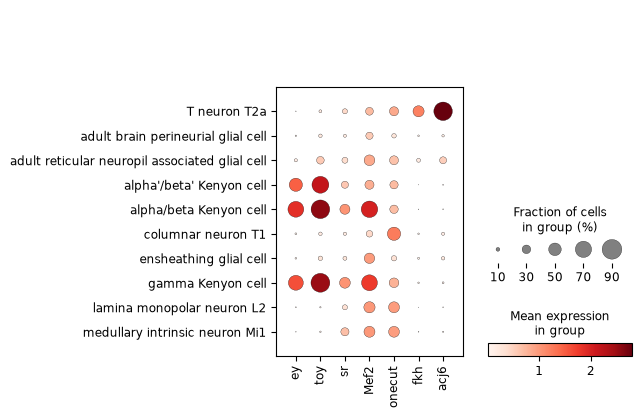

In [22]:
import scanpy as sc

from scripts.prepare_data import make_fca_brain_h5ad

expression = sc.read_h5ad(make_fca_brain_h5ad())

cell_types = [
    "gamma Kenyon cell", "alpha/beta Kenyon cell", "alpha'/beta' Kenyon cell",
    "columnar neuron T1", "T neuron T2a", "lamina monopolar neuron L2",
    "medullary intrinsic neuron Mi1",
    "ensheathing glial cell", "adult brain perineurial glial cell",
    "adult reticular neuropil associated glial cell",
]

# Not scaled per gene: the point is the absolute difference between a factor
# that is present and one that is not.
sc.pl.dotplot(
    expression[expression.obs["annotation"].isin(cell_types)],
    var_names=["ey", "toy", "sr", "Mef2", "onecut", "fkh", "acj6"],
    groupby="annotation",
)

- **`ey` and `toy` are Kenyon factors**, sharply so: 53 to 68 and 74 to 85 per
  cent of Kenyon cells, against under 10 per cent of every other type here. The
  Ey site Figure 4 mutated belongs to a factor that is demonstrably present
- **`acj6` and `fkh` are T2a factors**, and almost absent from Kenyon cells
- **`Mef2` is everywhere**, so a Mef2 site argues for no cell type on its own
- **`onecut` is broad across the optic lobe** and highest in T1

So plausibility depends on which cell type you are asking about, and this is
also how you choose which factors to scan for. The four used above, from Figure
4, are Kenyon cell factors. Scanning a Kenyon enhancer for `fkh` or `acj6` would
return hits, but the cell does not make either protein, so they could not be
binding sites. In a T2a enhancer the same two are exactly what you would look
for.

**Three things have to agree before a motif means much: the model leans on that
position, the match survives a calibrated test, and the factor is expressed in
the cell type the model named.**

## 7. Your turn

### Letting the scores choose the places

Up to here we chose the motifs and checked whether the model agreed. That works
when a paper has already given the answer, as for `enh47`, but it cannot be the
normal way round: you would only ever find the factors you thought to ask about.

So turn it over. Find the stretches the model leans on **first**, straight from
the contribution scores, and only then ask what each one is. `tangermeme` has
the seqlet caller from tf-modisco for exactly this. A **seqlet** is a short
stretch contributing more than chance would allow, found with no reference to
any motif database.

We also switch to **Embryo10x** here. Its contribution scores are clearer on
these sequences, and it names cell types directly, so you can choose factors to
look for without a lookup table.

In [23]:
all_seqs = crested.utils.fetch_sequences(list(tested["region"]), genome)
embryo_preds = crested.tl.predict(all_seqs, embryo_model, batch_size=32)

tested["embryo_call"] = [embryo_classes[i] for i in embryo_preds.argmax(axis=1)]
tested["embryo_score"] = embryo_preds.max(axis=1).round(2)

tested["embryo_call"].value_counts()

1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 439ms/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 331ms/step


embryo_call
Neuronal                17
Hemocytes                7
PNS_sens_neurons         7
Glia                     6
Head_Ectoderm            5
Somatic_muscles          3
Visceral_muscles         2
Salivary_gland           2
Midgut_acidification     1
Yolk                     1
Fat_body                 1
Epidermis                1
Hindgut                  1
Name: count, dtype: int64

Most of these regions look neuronal to the embryo model, which is unsurprising
for sequences taken from a brain. Six are called glial, and those are the
clearest to read, so start there.

**Name the stretches with factors that belong to the cell type the model
chose.** Any fly transcription factor in the database can be named: `gcm` and
`repo` for glia, `onecut` or `acj6` for neurons, the Figure 4 four for Kenyon
cells. Picking factors that are not made in that cell type will still produce
matches, and they will mean nothing.

In [24]:
from tangermeme.seqlet import recursive_seqlets


def where_the_model_looks(contributions, sequence, tfs, p_value=0.01):
    """The stretches the model leans on, named only where a name really fits."""
    importance = np.abs(contributions[0, 0]).sum(axis=1)

    # Found from the contribution scores alone. No motif database involved.
    seqlets = recursive_seqlets(importance[None], threshold=p_value)

    # A stretch is named only if a significant match covers at least half the
    # matrix. Accepting any overlap at all lets an eleven-nucleotide matrix
    # claim a four-nucleotide stretch, which produces confident nonsense.
    hits = fimo_scan(sequence, tfs, p_value=1e-3)
    rows = []
    for s in seqlets.itertuples():
        start, end = int(s.start), int(s.end)
        best = None
        for h in hits.itertuples():
            covered = min(end, int(h.end)) - max(start, int(h.start))
            if covered >= 0.5 * (int(h.end) - int(h.start)):
                if best is None or h.score > best.score:
                    best = h
        rows.append({
            "start": start, "end": end,
            "tf": best.tf if best is not None else "unnamed",
            "x_average": round(float(importance[start:end].mean() / importance.mean()), 2),
        })
    return pd.DataFrame(rows).sort_values("start").reset_index(drop=True)

enh23: chr2L:828614-829114, called Glia at 0.63
2026-10-21T17:21:29.559764+0200 INFO Calculating contribution scores for 1 region(s) and 1 class(es).


Model:   0%|          | 0/1 [00:00<?, ?it/s]

Model: 100%|██████████| 1/1 [00:07<00:00,  7.90s/it]

Model: 100%|██████████| 1/1 [00:07<00:00,  7.90s/it]

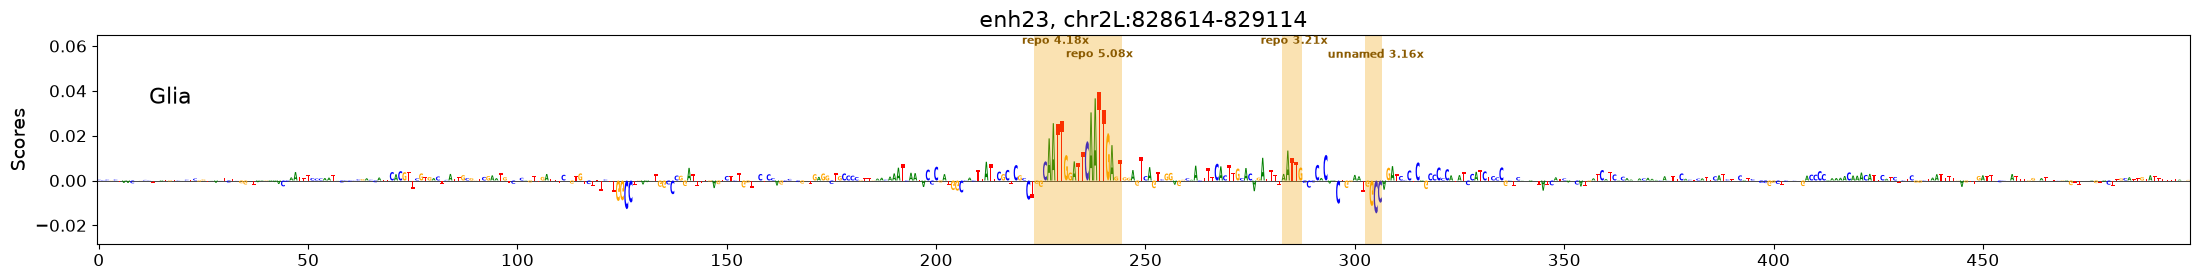

,start,end,tf,x_average
0,224,233,repo,4.18
1,233,245,repo,5.08
2,283,288,repo,3.21
3,303,307,unnamed,3.16


In [25]:
PICK = "enh23"                       # change this
TFS = ["gcm", "repo", "pros"]        # factors for the cell type the model names

row = tested.loc[tested["name"] == PICK].iloc[0]
pick_seq = crested.utils.fetch_sequences([row["region"]], genome)[0]
pick_class = embryo_classes.index(row["embryo_call"])
print(f"{PICK}: {row['region']}, called {row['embryo_call']} at {row['embryo_score']:.2f}")

pick_scores, pick_onehot = crested.tl.contribution_scores(
    [pick_seq], target_idx=pick_class, model=embryo_model,
    method="expected_integrated_grad",
    simplex_correction=True, genome=genome,
)

pick_found = where_the_model_looks(pick_scores, pick_seq, TFS)
plot_with_motifs(pick_scores, pick_onehot, pick_found,
                 f"{PICK}, {row['region']}", row["embryo_call"])
pick_found

Three of the four stretches are **`repo`** sites, at three to five times the
average contribution.

`repo` is the transcription factor that makes a fly glial cell glial. It is
required for glial differentiation, and Practical 5 used it as *the* glial
marker gene. The model was given 500 nucleotides, called the region glial, and
the positions it depends on are the binding sites of the factor that defines
that cell type. Nothing told it about `repo`; it learned those sites from
accessibility data.

Questions to ask about your own plot:

- **Which stretches got a name, and which did not?** An unnamed one is something
  the model relies on that your chosen factors cannot explain
- **Is the factor expressed in that cell type?** Use the dot plot above
- Is the signal concentrated in a few stretches, or spread across many?

### Or a region of your own

> **Optional.**

This is the natural starting point for the group project. Use one you found in
Practical 5, or edit the coordinates below. The region must be exactly 500 bp:
the centre of a peak, 250 bp either side.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


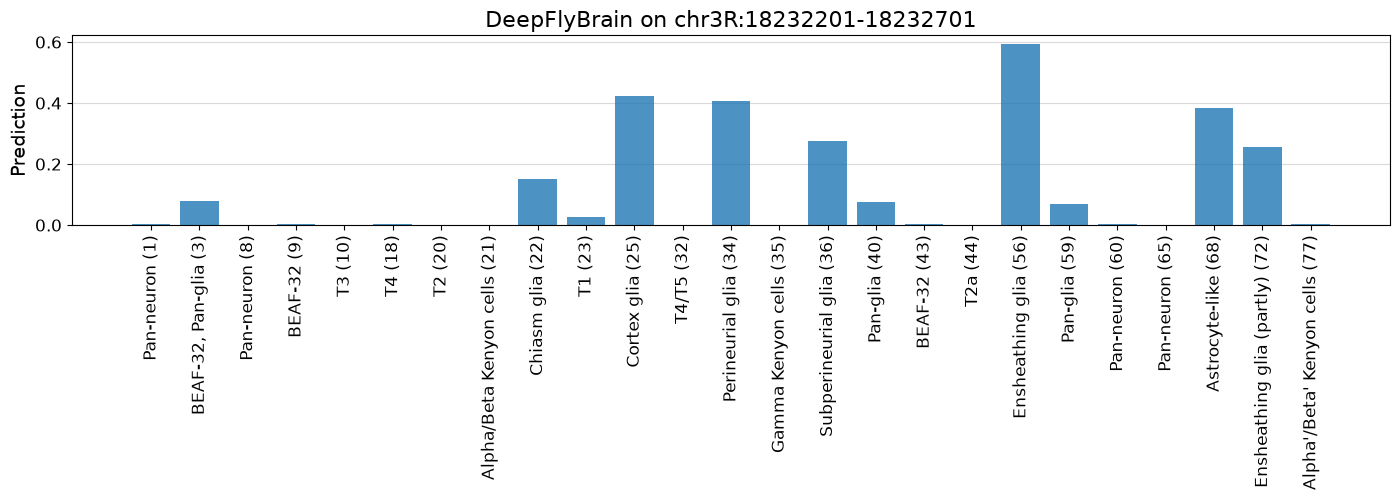

In [26]:
MY_REGION = "chr3R:18232201-18232701"     # change this

my_seq = crested.utils.fetch_sequences([MY_REGION], genome)[0]

crested.pl.region.bar(
    data=crested.tl.predict(my_seq, model).ravel()[topic_index],
    classes=topic_labels, title=f"DeepFlyBrain on {MY_REGION}",
    width=14, height=5, xtick_rotation=90,
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


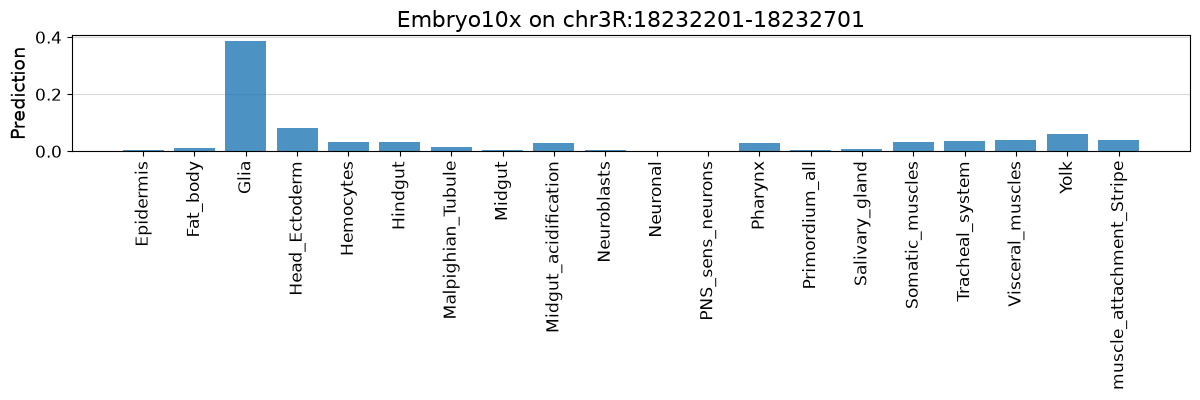

In [27]:
crested.pl.region.bar(
    data=crested.tl.predict(my_seq, embryo_model).ravel(),
    classes=embryo_classes, title=f"Embryo10x on {MY_REGION}",
    width=12, height=4, xtick_rotation=90,
)

Questions to ask about your plots:

- Are any bars tall? If everything is near zero in both models, neither
  recognises the region
- Do the tall bars agree with the cell type whose bigwig showed the peak in
  Practical 5?

To see which nucleotides drove your result, put `MY_REGION` through the
contribution score cells in section 6.

## 8. What these models cannot do

- **Each knows only its own cells.** Neither has a dopaminergic class, and
  neither was trained on the larval brain
- **Most of the 81 topics are unannotated.** A confident prediction for one of
  those cannot be read
- **They report resemblance, not causation.** Showing that a region is an
  enhancer needs the experiment: clone the 500 bp in front of a reporter and
  look at the fly
- **Contribution scores are the model's reasoning, not the cell's**

## Summary

You gave 500 bp of DNA to two pretrained networks and asked which cell type it
belongs to and which nucleotides decided that. On an enhancer the authors had
dissected in flies, the model leaned on the sites they had mutated. Three things
had to agree before a motif meant anything: the model leans on the position, the
match survives a calibrated test, and the factor is expressed in that cell type.

**For the group project**, keep: the region, its prediction plots from both
models, the contribution score figure, and one sentence on what you think binds
there and why.